In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
np.random.seed(42)

In [3]:
students = pd.read_csv("studentz.csv")

In [4]:
students

,hours_studied,attendance_pct,previous_score,passed
0,3.7,43.0,33.0,0
1,9.5,72.0,41.0,1
2,7.3,72.0,33.0,1
3,6.0,78.0,27.0,0
4,1.6,84.0,29.0,0
...,...,...,...,...
295,5.2,68.0,35.0,0
296,7.7,80.0,42.0,1
297,2.2,50.0,87.0,0
298,6.2,52.0,21.0,0


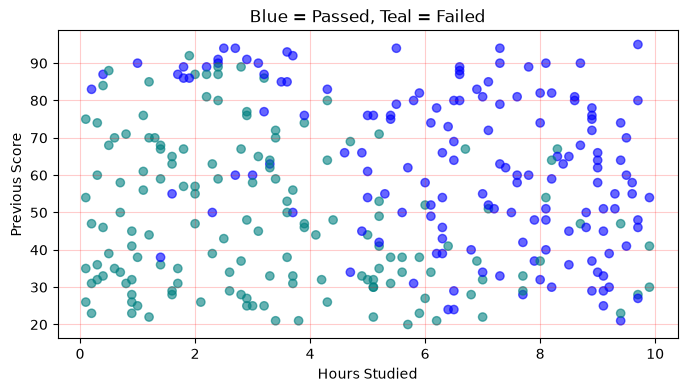

In [5]:
plt.figure(figsize=(8, 4))
colors = students["passed"].map({0: "teal", 1: "blue"})
plt.scatter(students["hours_studied"], students["previous_score"], c=colors, alpha=0.6)
plt.xlabel("Hours Studied")
plt.ylabel("Previous Score")
plt.title("Blue = Passed, Teal = Failed")
plt.grid(alpha=0.2, color = "red")
plt.show()

In [6]:
X = students.drop(columns="passed")
y = students["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,test_size=0.2, random_state=42, stratify=y     
)

print("X Train:", X_train.shape, "X Test:", X_test.shape)
print("Y Train:", y_train.shape, "Y Test:", y_test.shape)

X Train: (240, 3) X Test: (60, 3)
Y Train: (240,) Y Test: (60,)


In [7]:
log_model = make_pipeline(StandardScaler(), LogisticRegression())
log_model.fit(X_train, y_train)

log_pred = log_model.predict(X_test)
print("Logistic Regressionnaccuracy:", round(accuracy_score(y_test, log_pred), 3))

Logistic Regressionnaccuracy: 0.917


In [8]:
new_student = pd.DataFrame({"hours_studied": [6], "attendance_pct": [85], "previous_score": [60]})

print("Predicted class:", log_model.predict(new_student)[0], "(1 = pass, 0 = fail)")
proba = log_model.predict_proba(new_student)[0]
print(f"Probability of failing: {proba [0]:.2f}")
print(f"Probability of passing: {proba [1]:.2f}")

Predicted class: 1 (1 = pass, 0 = fail)
Probability of failing: 0.07
Probability of passing: 0.93


In [9]:
tree_model = DecisionTreeClassifier(max_depth=6, random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
print("Decision Tree accuracy:", round(accuracy_score(y_test, tree_pred), 3))

Decision Tree accuracy: 0.817


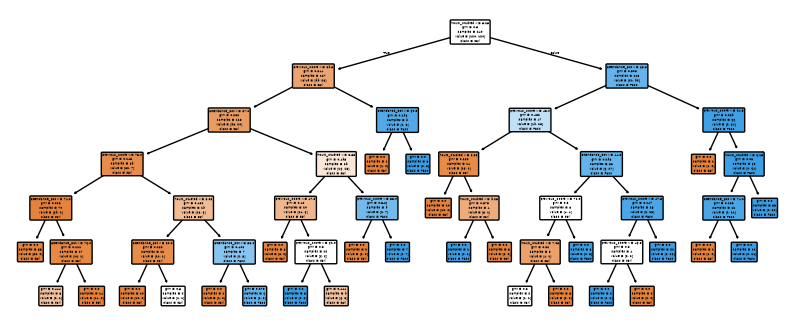

In [10]:
plt.figure(figsize=(10, 4))
plot_tree(tree_model, feature_names=X.columns, class_names=["Fail", "Pass"], filled=True, rounded=True)
plt.show()

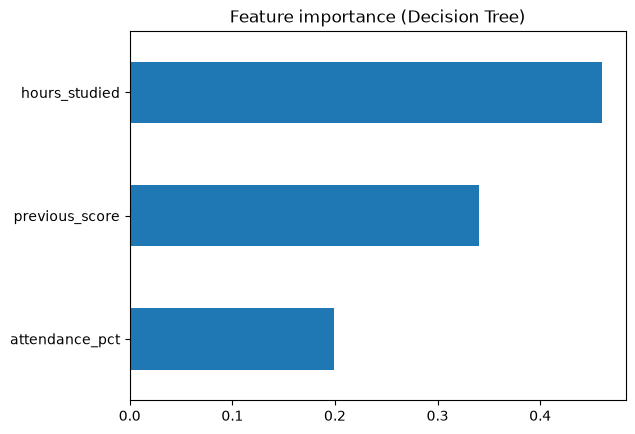

In [11]:
#which features did the tree find most usefull?
importance = pd.Series(tree_model.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", title="Feature importance (Decision Tree)")
plt.show()

In [12]:
#K_Nearest Neighbours
knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)
print("KNN accuracy:", round(accuracy_score(y_test, knn_pred), 3))

KNN accuracy: 0.867


In [13]:
knn_no_scaling = KNeighborsClassifier(n_neighbors=5)
knn_no_scaling.fit(X_train, y_train)

print("kNN WITHOUT scaling:", round(accuracy_score(y_test, knn_no_scaling.predict(X_test)), 3))
print("KNN WITH scaling:   ", round(accuracy_score(y_test, knn_pred), 3))

kNN WITHOUT scaling: 0.767
KNN WITH scaling:    0.867


In [14]:
#comparison between the three models 
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "KNN"], 
    "Accuracy": [
        accuracy_score(y_test, log_pred), 
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, knn_pred),
    ], 
}).round(3)
comparison.sort_values("Accuracy", ascending=False)

,Model,Accuracy
0,Logistic Regression,0.917
2,KNN,0.867
1,Decision Tree,0.817


In [15]:
#same student, three option
for name, mdl in [("Logistic Regression", log_model), ("Decision Tree", tree_model), ("KNN", knn_model)]:
    label = "Pass" if mdl.predict(new_student)[0] == 1 else "Fail"
    print(f"{name:20s} -> {label}")

Logistic Regression  -> Pass
Decision Tree        -> Pass
KNN                  -> Pass


In [16]:
#Using a real data set
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
Xc, yc = cancer.data, cancer.target

print("Shape:", Xc.shape)
print("Classes:", dict(zip(cancer.target_names, [0, 1])))
Xc.iloc[:3, :5]

Shape: (569, 30)
Classes: {np.str_('malignant'): 0, np.str_('benign'): 1}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,17.99,10.38,122.8,1001.0,0.11840
1,20.57,17.77,132.9,1326.0,0.08474
2,19.69,21.25,130.0,1203.0,0.10960


In [17]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
cancer_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cancer_model.fit(Xc_train, yc_train)

print("Accuracy on unseen patients:", round(accuracy_score(yc_test, cancer_model.predict(Xc_test)), 3))

Accuracy on unseen patients: 0.982
